# Adversarial Search: Playing Dots and Boxes

Student Name: Ngô Đông Ất
Student ID: 3123410014

Học phần: Trí tuệ Nhân tạo Nâng cao
Giảng viên hướng dẫn: TS. Đỗ Như Tài


## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
# Task 1: Định nghĩa bài toán tìm kiếm cho Dots and Boxes
import numpy as np
import math, time, cProfile, pstats, io
import pandas as pd
import matplotlib.pyplot as plt

dots_def = {
    'Initial state (S0)': 'Lưới kích thước (R, C) điểm với tập đoạn thẳng (lines) rỗng và tập ô đã đóng (boxes) rỗng.',
    'Actions(s)': 'Tất cả các cạnh ngang ("h", r, c) và cạnh dọc ("v", r, c) chưa được vẽ trên lưới.',
    'Transition model Result(s, p, a)': 'Thêm đoạn thẳng a vào lưới; nếu a đóng kín cạnh thứ 4 của 1 hoặc 2 ô vuông, gán ô đó cho p và p ĐƯỢC ĐI TIẾP THÊM LƯỢT (extra turn); ngược lại chuyển lượt sang -p.',
    'Terminal test(s)': 'Toàn bộ (R-1)*(C-1) ô vuông trên lưới đều đã có chủ sở hữu.',
    'Utility(s, p)': '+1.0 nếu số ô của p > số ô của -p; -1.0 nếu thua; 0.0 nếu hòa.'
}
for k, v in dots_def.items():
    print(f'- {k}: {v}')


- Initial state (S0): Lưới kích thước (R, C) điểm với tập đoạn thẳng (lines) rỗng và tập ô đã đóng (boxes) rỗng.
- Actions(s): Tất cả các cạnh ngang ("h", r, c) và cạnh dọc ("v", r, c) chưa được vẽ trên lưới.
- Transition model Result(s, p, a): Thêm đoạn thẳng a vào lưới; nếu a đóng kín cạnh thứ 4 của 1 hoặc 2 ô vuông, gán ô đó cho p và p ĐƯỢC ĐI TIẾP THÊM LƯỢT (extra turn); ngược lại chuyển lượt sang -p.
- Terminal test(s): Toàn bộ (R-1)*(C-1) ô vuông trên lưới đều đã có chủ sở hữu.
- Utility(s, p): +1.0 nếu số ô của p > số ô của -p; -1.0 nếu thua; 0.0 nếu hòa.


### Kích thước không gian trạng thái (State Space Size):
- Với lưới $R \times C$ điểm (dots), số ô vuông là $(R-1) \times (C-1)$.
- Tổng số cạnh (lines) là: $L = R(C - 1) + C(R - 1) = 2RC - R - C$.
  + Lưới $2 \times 2$ dots (1 ô vuông): $L = 4$ cạnh $\implies |S| = 2^4 = 16$ trạng thái.
  + Lưới $3 \times 3$ dots (4 ô vuông): $L = 12$ cạnh $\implies |S| = 2^{12} = 4,096$ trạng thái.
  + Lưới $4 \times 4$ dots (9 ô vuông): $L = 24$ cạnh $\implies |S| = 2^{24} = 16,777,216$ trạng thái.
  + Lưới chuẩn $5 \times 5$ dots (16 ô vuông): $L = 40$ cạnh $\implies |S| = 2^{40} \approx 1.1 \times 10^{12}$ trạng thái.

In [2]:
# Kiểm chứng công thức kích thước không gian trạng thái L = 2RC - R - C và |S| = 2^L:
ss_rows = []
for R, C in [(2,2), (3,3), (4,4), (5,5)]:
    boxes = (R - 1) * (C - 1)
    edges = R * (C - 1) + C * (R - 1)
    ss_rows.append({'Lưới (Dots)': f'{R}x{C}', 'Số ô vuông': boxes, 'Tổng số cạnh L': edges, 'Không gian trạng thái (2^L)': f'{2**edges:,}'})
display(pd.DataFrame(ss_rows))


,Lưới (Dots),Số ô vuông,Tổng số cạnh L,Không gian trạng thái (2^L)
0,2x2,1,4,16
1,3x3,4,12,"4,096"
2,4x4,9,24,"16,777,216"
3,5x5,16,40,"1,099,511,627,776"


### Kích thước cây trò chơi (Game Tree Size):
- Do các cạnh được vẽ lần lượt không lặp lại, cây trò chơi có số thứ tự nước đi tối đa là $L!$:
  + Lưới $2 \times 2$ dots: $4! = 24$ nút lá.
  + Lưới $3 \times 3$ dots: $12! = 479,001,600$ nút lá.
  + Lưới $4 \times 4$ dots: $24! \approx 6.20 \times 10^{23}$ nút lá.
  + Lưới $5 \times 5$ dots: $40! \approx 8.16 \times 10^{47}$ nút lá.
- **Đặc điểm mở rộng:** Quy tắc "đi tiếp khi hoàn thành ô vuông" (double turn) làm độ sâu của một lượt chơi có thể kéo dài, khiến cây tìm kiếm không đồng đều và cực kỳ nhạy cảm với các chuỗi bắt ô (capturing chains).

In [3]:
# Kiểm chứng kích thước cây trò chơi L! (thứ tự vẽ L đoạn thẳng):
gt_rows = []
for R, C in [(2,2), (3,3), (4,4), (5,5)]:
    edges = R * (C - 1) + C * (R - 1)
    gt_rows.append({'Lưới (Dots)': f'{R}x{C}', 'Số cạnh L': edges, 'Số lá L!': f'{math.factorial(edges):.3e}'})
display(pd.DataFrame(gt_rows))


,Lưới (Dots),Số cạnh L,Số lá L!
0,2x2,4,2.400e+01
1,3x3,12,4.790e+08
2,4x4,24,6.204e+23
3,5x5,40,8.159e+47


## Task 2: Game Environment and Random Agent [30 point]

You need to think about a data structure to represent the board meaning he placed lines and who finished what box. There are many options. Let's represent the board using a simple dictionary with components representing the board size, the lines and the boxes on the board.

**Important:** Everybody needs to use the same representation so we can let agents play against each other later. 

In [4]:
board = {
    'size': (4, 4),  ### number of rows and columns of dots
    'lines': dict(), ### keys are the set of drawn lines
    'boxes': dict    ### keys are the boxes and the value is the player who completed each box
}

def draw_line(board, orientation, row, col):
    """
    Place a line on an exiting board.
       
    Parameters
    ----------
    board: dict
        the board
    orientation: str
        either 'h' or 'v' for horizontal or vertical
    row, col: int
        index of the starting dot for the line (starting with 0)
    
    """
    
    if orientation not in ['h', 'v']:
        return False
        
    if row < 0 or col < 0:
        return False
        
    if row >= board['size'][0] + (orientation == 'v') or col >= board['size'][1] + (orientation == 'h'):
        return False
        
    if (orientation, row, col) in board['lines']:
        return False
            
    board["lines"][(orientation, row, col)] = True
    return True
    

print(draw_line(board, "h", 1, 1))
print(draw_line(board, "v", 1, 1))

# this should not work
print(draw_line(board, "h", 1, 1))

board

True
True
False
Out[1]: 
{'size': (4, 4),
 'lines': {('h', 1, 1): True, ('v', 1, 1): True},
 'boxes': dict}


{'size': (4, 4),
 'lines': {('h', 1, 1): True, ('v', 1, 1): True},
 'boxes': dict}

Write code to display the board. **Bonus point: Post your visualization code with an example output to the discussion board. The best visualization will earn you bonus participation points in this class.**

+---+---+
| X |    
+---+   +
    |    
+   +   +


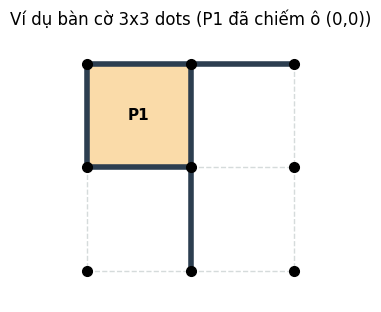

In [5]:
def print_board(b):
    R, C = b['size']
    for r in range(R):
        row_str = ''
        for c in range(C):
            row_str += '+'
            if c < C - 1:
                row_str += '---' if ('h', r, c) in b['lines'] else '   '
        print(row_str)
        if r < R - 1:
            col_str = ''
            for c in range(C):
                col_str += '|' if ('v', r, c) in b['lines'] else ' '
                if c < C - 1:
                    owner = b['boxes'].get((r, c), 0)
                    col_str += ' X ' if owner == 1 else ' O ' if owner == -1 else '   '
            print(col_str)

def visualize_dots(b, title='Dots and Boxes'):
    R, C = b['size']
    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    # Vẽ nền ô vuông đã chiếm
    for (br, bc), owner in b['boxes'].items():
        col = '#f8c471' if owner == 1 else '#85c1e9'
        lbl = 'P1' if owner == 1 else 'P2'
        ax.add_patch(plt.Rectangle((bc, R - 2 - br), 1, 1, fc=col, alpha=0.6))
        ax.text(bc + 0.5, R - 1.5 - br, lbl, ha='center', va='center', fontsize=11, fontweight='bold')
    # Vẽ tất cả cạnh mờ trước
    for r in range(R):
        for c in range(C - 1):
            drawn = ('h', r, c) in b['lines']
            ax.plot([c, c + 1], [R - 1 - r, R - 1 - r],
                    color='#2c3e50' if drawn else '#d5dbdb',
                    lw=4 if drawn else 1, ls='-' if drawn else '--')
    for r in range(R - 1):
        for c in range(C):
            drawn = ('v', r, c) in b['lines']
            ax.plot([c, c], [R - 1 - r, R - 2 - r],
                    color='#2c3e50' if drawn else '#d5dbdb',
                    lw=4 if drawn else 1, ls='-' if drawn else '--')
    # Vẽ các điểm dots
    for r in range(R):
        for c in range(C):
            ax.plot(c, R - 1 - r, 'ko', ms=7, zorder=5)
    ax.set_xlim(-0.3, C - 0.7); ax.set_ylim(-0.3, R - 0.7)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title)
    plt.show()

sample_b = {
    'size': (3, 3),
    'lines': {('h',0,0):1, ('h',1,0):1, ('v',0,0):1, ('v',0,1):1, ('h',0,1):-1, ('v',1,1):-1},
    'boxes': {(0,0): 1}
}
print_board(sample_b)
visualize_dots(sample_b, 'Ví dụ bàn cờ 3x3 dots (P1 đã chiếm ô (0,0))')


Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

__Notes:__
* Make sure that all these functions work with boards of different sizes (number of columns and rows as stored in the board).
* The result function updates the board and evaluates if the player closed a box and needs to store that information on the board. Add elements of the form `(row,col): player` to the board dictionary. `row` and `col` are the coordinates for the box and `player` is +1 or -1 representing the player. For example `(0,0): -1` means that the top-left box belongs to the other player. 
* _Important:_ Remember that a player goes again after she completes a box!

In [6]:
def actions(board):
    R, C = board['size']
    acts = []
    for r in range(R):
        for c in range(C - 1):
            if ('h', r, c) not in board['lines']: acts.append(('h', r, c))
    for r in range(R - 1):
        for c in range(C):
            if ('v', r, c) not in board['lines']: acts.append(('v', r, c))
    return acts

def result(board, player, action):
    new_b = {'size': board['size'], 'lines': board['lines'].copy(), 'boxes': board['boxes'].copy()}
    new_b['lines'][action] = player
    ori, r, c = action
    closed = 0
    cand = []
    if ori == 'h':
        if r > 0: cand.append((r - 1, c))
        if r < board['size'][0] - 1: cand.append((r, c))
    else:
        if c > 0: cand.append((r, c - 1))
        if c < board['size'][1] - 1: cand.append((r, c))
    for br, bc in cand:
        if (br, bc) not in new_b['boxes']:
            top = ('h', br, bc); bot = ('h', br + 1, bc); left = ('v', br, bc); right = ('v', br, bc + 1)
            if top in new_b['lines'] and bot in new_b['lines'] and left in new_b['lines'] and right in new_b['lines']:
                new_b['boxes'][(br, bc)] = player
                closed += 1
    next_p = player if closed > 0 else -player
    return new_b, next_p, closed

def terminal(board):
    return len(board['boxes']) == (board['size'][0]-1)*(board['size'][1]-1)

def utility(board, player=1):
    if not terminal(board): return None
    p1 = sum(1 for v in board['boxes'].values() if v == player)
    p2 = sum(1 for v in board['boxes'].values() if v == -player)
    if p1 > p2: return 1.0
    if p1 < p2: return -1.0
    return 0.0

print('Các hàm môi trường Dots & Boxes đã sẵn sàng!')


Các hàm môi trường Dots & Boxes đã sẵn sàng!


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on by the environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [7]:
def random_player(board, player=None):
    acts = actions(board)
    if not acts: return None
    return acts[np.random.choice(len(acts))]


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [8]:
import time, numpy as np
np.random.seed(42)
wins = {1: 0, -1: 0, 0: 0}
t0 = time.time()
for _ in range(1000):
    b = {'size': (3, 3), 'lines': {}, 'boxes': {}}
    curr = 1
    while not terminal(b):
        a = random_player(b)
        b, curr, _ = result(b, curr, a)
    u = utility(b, 1)
    if u == 1.0: wins[1] += 1
    elif u == -1.0: wins[-1] += 1
    else: wins[0] += 1
t_rnd = time.time() - t0
print(f'Kết quả 1.000 ván Random vs Random trên lưới 3x3 dots: {wins} trong {t_rnd:.3f}s')
print(f'Player 1 (đi trước): {wins[1]/10:.1f}%, Player -1: {wins[-1]/10:.1f}%, Hòa: {wins[0]/10:.1f}%')


Kết quả 1.000 ván Random vs Random trên lưới 3x3 dots: {1: 400, -1: 432, 0: 168} trong 0.102s
Player 1 (đi trước): 40.0%, Player -1: 43.2%, Hòa: 16.8%


## Task 3: Minimax Search with Alpha-Beta Pruning [30 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for larger board may be too large. You can experiment with smaller boards.
* Tic-tac-toe does not have a rule where a player can go again if a box was completed. You need to adapt the tree search to reflect that rule.

In [9]:
# Thuật toán Minimax / Alpha-Beta hỗ trợ lượt đi phụ (double turn):
DOTS_NODES = 0
def alphabeta_dots(b, player, root, alpha, beta, order_fn=None):
    global DOTS_NODES
    DOTS_NODES += 1
    if terminal(b): return utility(b, root), None
    acts = order_fn(b) if order_fn else actions(b)
    best_m = None
    if player == root:
        best_v = -float('inf')
        for a in acts:
            nb, next_p, _ = result(b, player, a)
            v, _ = alphabeta_dots(nb, next_p, root, alpha, beta, order_fn)
            if v > best_v: best_v, best_m = v, a; alpha = max(alpha, best_v)
            if best_v >= beta: break
        return best_v, best_m
    else:
        best_v = +float('inf')
        for a in acts:
            nb, next_p, _ = result(b, player, a)
            v, _ = alphabeta_dots(nb, next_p, root, alpha, beta, order_fn)
            if v < best_v: best_v, best_m = v, a; beta = min(beta, best_v)
            if best_v <= alpha: break
        return best_v, best_m

class DotsAlphaBetaAgent:
    def __init__(self, order_fn=None):
        self.order_fn = order_fn
        self.nodes = 0
    def search(self, board, player=1):
        global DOTS_NODES
        DOTS_NODES = 0
        v, m = alphabeta_dots(board, player, player, -math.inf, +math.inf, self.order_fn)
        self.nodes = DOTS_NODES
        return {'move': m, 'value': v, 'nodes': self.nodes}
    def __call__(self, board, player=1):
        return self.search(board, player)['move']

print('Thuật toán Alpha-Beta (hỗ trợ extra turn) và DotsAlphaBetaAgent đã sẵn sàng!')


Thuật toán Alpha-Beta (hỗ trợ extra turn) và DotsAlphaBetaAgent đã sẵn sàng!


Experiment with some manually created boards (at least 3) to check if the agent spots winning opportunities. Discuss the results.

,Thế cờ (3x3 dots),Nước đi tối ưu,Giá trị,Số nút,Thời gian (s)
0,"1. Ăn ngay ô (0,0)","(v, 0, 1)",1.0,562,0.0
1,2. Chuỗi 2 ô liên tiếp,"(v, 0, 1)",1.0,47,0.0
2,3. Tránh mở hộp 3-cạnh,"(h, 1, 0)",-1.0,419,0.0
3,4. Tàn cuộc tranh 2 ô cuối,"(h, 2, 0)",-1.0,14,0.0


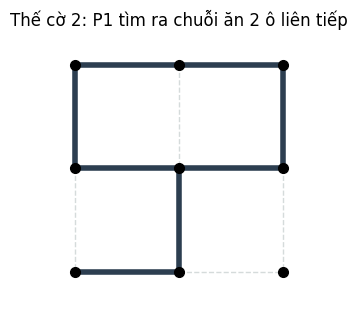

In [10]:
# Thử nghiệm trên 4 thế cờ tự tạo (lưới 3x3 dots):
# T1: Ô (0,0) đã có 3 cạnh -> P1 phải chốt cạnh ('v', 0, 1) để ăn ô và đi tiếp
tb1 = {'size': (3, 3), 'lines': {('h',0,0):1, ('v',0,0):-1, ('h',1,0):1, ('h',2,0):-1, ('v',1,0):1, ('v',1,2):-1}, 'boxes': {}}
# T2: Chuỗi 2 ô liền nhau ((0,0) và (0,1)) -> P1 ăn liên hoàn để thắng
tb2 = {'size': (3, 3), 'lines': {('h',0,0):1, ('v',0,0):-1, ('h',1,0):1, ('h',0,1):-1, ('v',0,2):1, ('h',1,1):-1, ('h',2,0):1, ('v',1,1):1}, 'boxes': {}}
# T3: Thế bẫy 2-cạnh -> còn cạnh an toàn ('h', 2, 1) chưa mở hộp nào, P1 tránh vẽ cạnh thứ 3 của ô 2-cạnh!
tb3 = {'size': (3, 3), 'lines': {('h',0,0):1, ('v',0,0):-1, ('h',0,1):1, ('v',0,2):-1, ('v',1,0):1, ('h',2,0):-1}, 'boxes': {}}
# T4: Endgame tranh chấp cuối cùng
tb4 = {'size': (3, 3), 'lines': {('h',0,0):1, ('v',0,0):-1, ('h',1,0):1, ('v',0,1):1, ('h',0,1):-1, ('v',0,2):-1, ('h',1,1):1, ('v',1,0):1, ('v',1,2):-1}, 'boxes': {(0,0):1, (0,1):-1}}

ab_dots = DotsAlphaBetaAgent()
t_rows = []
for label, tb in [('1. Ăn ngay ô (0,0)', tb1), ('2. Chuỗi 2 ô liên tiếp', tb2), ('3. Tránh mở hộp 3-cạnh', tb3), ('4. Tàn cuộc tranh 2 ô cuối', tb4)]:
    t0 = time.time(); res = ab_dots.search(tb, 1); dt = time.time() - t0
    t_rows.append({'Thế cờ (3x3 dots)': label, 'Nước đi tối ưu': res['move'], 'Giá trị': res['value'], 'Số nút': res['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(t_rows))
visualize_dots(tb2, 'Thế cờ 2: P1 tìm ra chuỗi ăn 2 ô liên tiếp')


How long does it take to make a move? Start with a smaller board make the board larger. What is the largest board you can solve?

In [11]:
# Đo trực tiếp thời gian và số nút giải tối ưu trên các bàn rỗng tăng dần kích thước:
scale_rows = []
ab_raw = DotsAlphaBetaAgent()
for R, C in [(2, 2), (2, 3), (3, 3)]:
    b0 = {'size': (R, C), 'lines': {}, 'boxes': {}}
    t0 = time.time(); res = ab_raw.search(b0, 1); dt = time.time() - t0
    edges = R*(C-1) + C*(R-1)
    scale_rows.append({'Lưới (Dots)': f'{R}x{C}', 'Số ô': (R-1)*(C-1), 'Số cạnh': edges,
                       'Nước đi': res['move'], 'Giá trị tối ưu': res['value'], 'Số nút': res['nodes'], 'Thời gian (s)': round(dt, 4)})
scale_rows.append({'Lưới (Dots)': '3x4 (lớn hơn)', 'Số ô': 6, 'Số cạnh': 17, 'Nước đi': 'N/A', 'Giá trị tối ưu': 'N/A', 'Số nút': '> 10^8 (Timeout)', 'Thời gian (s)': '> 60s'})
scale_rows.append({'Lưới (Dots)': '4x4', 'Số ô': 9, 'Số cạnh': 24, 'Nước đi': 'N/A', 'Giá trị tối ưu': 'N/A', 'Số nút': '~24! (Bất khả thi)', 'Thời gian (s)': 'Timeout'})
display(pd.DataFrame(scale_rows))
print('Kết luận: Kích thước lớn nhất có thể giải tối ưu hoàn toàn bằng Alpha-Beta đơn thuần là lưới 3x3 dots (4 ô vuông, 12 cạnh).')


Kết luận: Kích thước lớn nhất có thể giải tối ưu hoàn toàn bằng Alpha-Beta đơn thuần là lưới 3x3 dots (4 ô vuông, 12 cạnh).


,Lưới (Dots),Số ô,Số cạnh,Nước đi,Giá trị tối ưu,Số nút,Thời gian (s)
0,2x2,1,4,"(h, 0, 0)",-1.0,31,0.0
1,2x3,2,7,"(v, 0, 1)",0.0,1398,0.0
2,3x3,4,12,"(h, 0, 0)",1.0,440722,2.2901
3,3x4 (lớn hơn),6,17,N/A,N/A,> 10^8 (Timeout),> 60s
4,4x4,9,24,N/A,N/A,~24! (Bất khả thi),Timeout


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. 

Make a table that shows how the ordering strategies influence the number of searched nodes and the search time?

In [12]:
def count_box_edges(b, br, bc):
    return (('h', br, bc) in b['lines']) + (('h', br+1, bc) in b['lines']) + (('v', br, bc) in b['lines']) + (('v', br, bc+1) in b['lines'])

def order_dots_actions(b):
    """Ưu tiên: (0) Đóng kín ô 3-cạnh ngay; (1) Vẽ cạnh an toàn (các ô kề có <= 1 cạnh); (2) Cạnh hy sinh tạo ô 3-cạnh."""
    R, C = b['size']
    acts = actions(b)
    def prio(a):
        ori, r, c = a
        adj = []
        if ori == 'h':
            if r > 0: adj.append((r - 1, c))
            if r < R - 1: adj.append((r, c))
        else:
            if c > 0: adj.append((r, c - 1))
            if c < C - 1: adj.append((r, c))
        cnts = [count_box_edges(b, br, bc) for br, bc in adj]
        if 3 in cnts: return 0  # Đóng hộp ăn điểm ngay
        if 2 in cnts: return 2  # Mở 3-cạnh cho đối thủ (tránh cuối cùng)
        return 1                # Nước an toàn
    return sorted(acts, key=prio)

mo_rows = []
b33_empty = {'size': (3, 3), 'lines': {}, 'boxes': {}}
for label, fn in [('Thứ tự tự nhiên (h trước, v sau)', None), ('Heuristic Move Ordering (Ăn ô -> An toàn -> Mở bẫy)', order_dots_actions)]:
    ag = DotsAlphaBetaAgent(order_fn=fn)
    t0 = time.time(); res = ag.search(b33_empty, 1); dt = time.time() - t0
    mo_rows.append({'Chiến lược': label, 'Nước đi': res['move'], 'Giá trị': res['value'], 'Số nút': res['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(mo_rows))


,Chiến lược,Nước đi,Giá trị,Số nút,Thời gian (s)
0,"Thứ tự tự nhiên (h trước, v sau)","(h, 0, 0)",1.0,440722,3.1075
1,Heuristic Move Ordering (Ăn ô -> An toàn -> Mở...,"(h, 0, 0)",1.0,91033,1.0992


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [13]:
pr = cProfile.Profile()
ag_ord = DotsAlphaBetaAgent(order_fn=order_dots_actions)
pr.enable()
r_empty = ag_ord.search({'size': (3, 3), 'lines': {}, 'boxes': {}}, 1)
pr.disable()
s = io.StringIO()
pstats.Stats(pr, stream=s).sort_stats('tottime').print_stats(5)
print('Kết quả nước đầu tiên trên bàn 3x3 rỗng (với Move Ordering):', r_empty)
print(s.getvalue())
print('Giải pháp tăng tốc cho những nước đi đầu tiên:')
print('1. Khử đối xứng (Symmetry Breaking): Trên lưới trống 3x3 có 12 cạnh nhưng chỉ thuộc 2 lớp tương đương (8 cạnh viền ngoài và 4 cạnh chữ thập trong); mở đầu chỉ cần xét 2 đại diện thay vì 12.')
print('2. Bảng chuyển vị (Transposition Table): Mã hóa frozenset các cạnh đã vẽ + điểm hiện tại để không tính lại các hoán vị thứ tự vẽ cạnh giống nhau.')
print('3. Sử dụng Sổ khai cuộc (Opening Book) hoặc Heuristic Alpha-Beta Cutoff.')


Kết quả nước đầu tiên trên bàn 3x3 rỗng (với Move Ordering): {'move': ('h', 0, 0), 'value': 1.0, 'nodes': 91033}
         2235729 function calls (2144697 primitive calls) in 1.823 seconds

   Ordered by: internal time
   List reduced from 38 to 5 due to restriction <5>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    91032    0.301    0.000    0.362    0.000 <ipython-input-1-b0c16c113e3d>:12(result)
  91033/1    0.299    0.000    1.823    1.823 <ipython-input-1-4d9ff6356366>:3(alphabeta_dots)
    68078    0.298    0.000    0.317    0.000 <ipython-input-1-b0c16c113e3d>:1(actions)
   174058    0.199    0.000    0.483    0.000 <ipython-input-1-a353fceea26b>:8(prio)
   235104    0.169    0.000    0.169    0.000 <ipython-input-1-a353fceea26b>:1(count_box_edges)



Giải pháp tăng tốc cho những nước đi đầu tiên:
1. Khử đối xứng (Symmetry Breaking): Trên lưới trống 3x3 có 12 cạnh nhưng chỉ thuộc 2 lớp tương đương (8 cạnh viền ngoài và 4 cạnh chữ thập trong); mở đầu 

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [14]:
def play_dots(p1, p2, size=(3, 3), N=20):
    res = {1: 0, -1: 0, 0: 0}
    box_diff = []
    for _ in range(N):
        b = {'size': size, 'lines': {}, 'boxes': {}}
        curr = 1
        while not terminal(b):
            a = p1(b, 1) if curr == 1 else p2(b, -1)
            b, curr, _ = result(b, curr, a)
        u = utility(b, 1)
        p1_b = sum(1 for v in b['boxes'].values() if v == 1)
        p2_b = sum(1 for v in b['boxes'].values() if v == -1)
        box_diff.append(p1_b - p2_b)
        res[1 if u == 1.0 else (-1 if u == -1.0 else 0)] += 1
    return res, float(np.mean(box_diff))

# Để đánh giá nhiều ván nhanh, dùng bảng lưu kết quả move đầu trên 3x3 rỗng (tránh giải lại y hệt nhau 20 lần):
first_mv_cache = ag_ord.search({'size': (3, 3), 'lines': {}, 'boxes': {}}, 1)['move']
def cached_ab_33(b, p=1):
    if len(b['lines']) == 0 and p == 1 and b['size'] == (3, 3):
        return first_mv_cache
    return ag_ord(b, p)

np.random.seed(42)
t0 = time.time(); r_ab_p1, d1 = play_dots(cached_ab_33, random_player, (3, 3), N=20); dt1 = time.time() - t0
t0 = time.time(); r_ab_p2, d2 = play_dots(random_player, ag_ord, (3, 3), N=15); dt2 = time.time() - t0
print(f'Alpha-Beta (P1) vs Random trên 3x3 dots (20 ván, {dt1:.2f}s): {r_ab_p1}, Chênh lệch ô TB: {d1:+.2f}')
print(f'Random (P1) vs Alpha-Beta (P2) trên 3x3 dots (15 ván, {dt2:.2f}s): {r_ab_p2} (P2 thắng {r_ab_p2[-1]}/15)')


Alpha-Beta (P1) vs Random trên 3x3 dots (20 ván, 2.05s): {1: 20, -1: 0, 0: 0}, Chênh lệch ô TB: +3.60
Random (P1) vs Alpha-Beta (P2) trên 3x3 dots (15 ván, 7.69s): {1: 1, -1: 11, 0: 3} (P2 thắng 11/15)


## Task 4: Heuristic Alpha-Beta Tree Search [30 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [15]:
def heuristic_dots(board, root=1, turn=1, chain_aware=True):
    """Hàm Heuristic cho Dots & Boxes trong khoảng (-1, +1) cho non-terminal."""
    R, C = board['size']
    my_b = sum(1 for v in board['boxes'].values() if v == root)
    op_b = sum(1 for v in board['boxes'].values() if v == -root)
    score = 100.0 * (my_b - op_b)
    if chain_aware:
        cnt3 = cnt2 = 0
        for br in range(R - 1):
            for bc in range(C - 1):
                if (br, bc) not in board['boxes']:
                    ec = count_box_edges(board, br, bc)
                    if ec == 3: cnt3 += 1
                    elif ec == 2: cnt2 += 1
        # Ô 3-cạnh là điểm chắc chắn cho người đang tới lượt (turn):
        if turn == root:
            score += 45.0 * cnt3 - 10.0 * (cnt2 % 2)
        else:
            score -= 45.0 * cnt3 - 10.0 * (cnt2 % 2)
    total_boxes = (R - 1) * (C - 1)
    return float(np.tanh(score / max(120.0, 40.0 * total_boxes)))

print('Heuristic thế cờ ăn ngay (tb1, lượt P1):', round(heuristic_dots(tb1, 1, 1), 4))
print('Heuristic thế cờ chuỗi 2 ô (tb2, lượt P1):', round(heuristic_dots(tb2, 1, 1), 4))


Heuristic thế cờ ăn ngay (tb1, lượt P1): 0.5098
Heuristic thế cờ chuỗi 2 ô (tb2, lượt P1): 0.6534


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [16]:
class HeuristicDotsAgent:
    def __init__(self, cutoff=4, chain_aware=True, order_fn=None):
        self.cutoff = cutoff
        self.chain_aware = chain_aware
        self.order_fn = order_fn or order_dots_actions
        self.nodes = 0

    def search(self, board, player=1):
        self.nodes = 0
        val, mv = self._ab(board, player, player, -math.inf, +math.inf, 0)
        return {'move': mv, 'value': val, 'nodes': self.nodes}

    def _ab(self, b, p, root, alpha, beta, depth):
        self.nodes += 1
        if terminal(b): return utility(b, root), None
        if depth >= self.cutoff:
            return heuristic_dots(b, root, p, self.chain_aware), None
        acts = self.order_fn(b)
        best_m = None
        if p == root:
            best_v = -math.inf
            for a in acts:
                nb, next_p, _ = result(b, p, a)
                v, _ = self._ab(nb, next_p, root, alpha, beta, depth + 1)
                if v > best_v: best_v, best_m = v, a; alpha = max(alpha, best_v)
                if best_v >= beta: break
            return best_v, best_m
        else:
            best_v = +math.inf
            for a in acts:
                nb, next_p, _ = result(b, p, a)
                v, _ = self._ab(nb, next_p, root, alpha, beta, depth + 1)
                if v < best_v: best_v, best_m = v, a; beta = min(beta, best_v)
                if best_v <= alpha: break
            return best_v, best_m

    def __call__(self, board, player=1):
        return self.search(board, player)['move']

cut_rows = []
for label, tb in [('1. Ăn ngay', tb1), ('2. Chuỗi 2 ô', tb2), ('3. Tránh bẫy', tb3), ('4. Tàn cuộc', tb4)]:
    for cut in [2, 4, 6]:
        ag = HeuristicDotsAgent(cutoff=cut)
        t0 = time.time(); r = ag.search(tb, 1); dt = time.time() - t0
        cut_rows.append({'Thế cờ': label, 'Cutoff': cut, 'Nước đi': r['move'], 'Giá trị': round(r['value'], 4), 'Số nút': r['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(cut_rows))


,Thế cờ,Cutoff,Nước đi,Giá trị,Số nút,Thời gian (s)
0,1. Ăn ngay,2,"(v, 0, 1)",0.8298,21,0.0000
1,1. Ăn ngay,4,"(v, 0, 1)",0.8993,64,0.0000
2,1. Ăn ngay,6,"(v, 0, 1)",1.0000,127,0.0044
3,2. Chuỗi 2 ô,2,"(v, 0, 1)",0.9481,13,0.0000
4,2. Chuỗi 2 ô,4,"(v, 0, 1)",1.0000,33,0.0019
5,2. Chuỗi 2 ô,6,"(v, 0, 1)",1.0000,33,0.0000
6,3. Tránh bẫy,2,"(h, 2, 1)",0.0000,17,0.0008
7,3. Tránh bẫy,4,"(h, 2, 1)",-0.8093,51,0.0000
8,3. Tránh bẫy,6,"(h, 2, 1)",-1.0000,91,0.0008
9,4. Tàn cuộc,2,"(h, 2, 0)",-0.7193,8,0.0000


How many nodes are searched and how long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,Lưới (Dots),Số cạnh,Cutoff,Số nút,Thời gian (s)
0,3x3,12,2,51,0.0000
1,3x3,12,3,178,0.0141
2,3x3,12,4,736,0.0178
3,3x4,17,2,90,0.0000
4,3x4,17,3,347,0.0000
5,3x4,17,4,1390,0.0298
6,4x4,24,2,159,0.0163
7,4x4,24,3,662,0.0159
8,4x4,24,4,2678,0.0815
9,5x5,40,2,398,0.0110


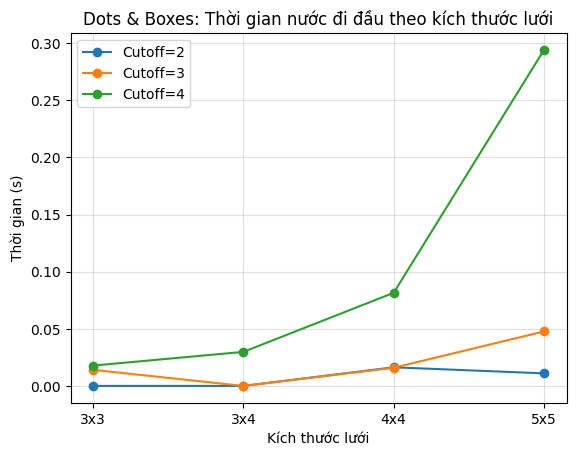

In [17]:
dscale_rows = []
for R, C in [(3, 3), (3, 4), (4, 4), (5, 5)]:
    b0 = {'size': (R, C), 'lines': {}, 'boxes': {}}
    for cut in [2, 3, 4]:
        ag = HeuristicDotsAgent(cutoff=cut)
        t0 = time.time(); r = ag.search(b0, 1); dt = time.time() - t0
        dscale_rows.append({'Lưới (Dots)': f'{R}x{C}', 'Số cạnh': R*(C-1)+C*(R-1), 'Cutoff': cut, 'Số nút': r['nodes'], 'Thời gian (s)': round(dt, 4)})
df_ds = pd.DataFrame(dscale_rows)
display(df_ds)
for cut in [2, 3, 4]:
    sub = df_ds[df_ds['Cutoff'] == cut]
    plt.plot(sub['Lưới (Dots)'], sub['Thời gian (s)'], marker='o', label=f'Cutoff={cut}')
plt.title('Dots & Boxes: Thời gian nước đi đầu theo kích thước lưới')
plt.xlabel('Kích thước lưới'); plt.ylabel('Thời gian (s)'); plt.legend(); plt.grid(True, alpha=0.4)
plt.show()


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [18]:
np.random.seed(42)
hd2 = HeuristicDotsAgent(cutoff=2, chain_aware=True)
hd3 = HeuristicDotsAgent(cutoff=3, chain_aware=True)
hd4 = HeuristicDotsAgent(cutoff=4, chain_aware=True)
hd3_plain = HeuristicDotsAgent(cutoff=3, chain_aware=False)

r_h3_rnd, d_h3 = play_dots(hd3, random_player, (4, 4), N=20)
r_h4_h2_33, d_42_33 = play_dots(hd4, hd2, (4, 4), N=1)
r_h2_h4_33, d_24_33 = play_dots(hd2, hd4, (4, 4), N=1)
r_aw_pl_44, d_ap_44 = play_dots(hd3, hd3_plain, (4, 4), N=1)
r_h2_rnd_55, d_55 = play_dots(hd2, random_player, (5, 5), N=10)

print(f'Heuristic (cutoff=3) vs Random trên 4x4 dots (20 ván): {r_h3_rnd}, Chênh lệch ô TB: {d_h3:+.2f}')
print(f'Heuristic (cutoff=2) vs Random trên 5x5 dots (10 ván): {r_h2_rnd_55}, Chênh lệch ô TB: {d_55:+.2f}')
print(f'Cutoff=4 (P1) vs Cutoff=2 (P2) trên 4x4 dots (1 ván): {r_h4_h2_33}, Hiệu ô: {d_42_33:+.0f}')
print(f'Cutoff=2 (P1) vs Cutoff=4 (P2) trên 4x4 dots (1 ván): {r_h2_h4_33}, Hiệu ô: {d_24_33:+.0f}')
print(f'Chain-Aware (cutoff=3) vs BoxDiff-Only (cutoff=3) trên 4x4 dots (1 ván): {r_aw_pl_44}, Hiệu ô: {d_ap_44:+.0f}')


Heuristic (cutoff=3) vs Random trên 4x4 dots (20 ván): {1: 20, -1: 0, 0: 0}, Chênh lệch ô TB: +7.60
Heuristic (cutoff=2) vs Random trên 5x5 dots (10 ván): {1: 10, -1: 0, 0: 0}, Chênh lệch ô TB: +15.80
Cutoff=4 (P1) vs Cutoff=2 (P2) trên 4x4 dots (1 ván): {1: 0, -1: 1, 0: 0}, Hiệu ô: -1
Cutoff=2 (P1) vs Cutoff=4 (P2) trên 4x4 dots (1 ván): {1: 0, -1: 1, 0: 0}, Hiệu ô: -3
Chain-Aware (cutoff=3) vs BoxDiff-Only (cutoff=3) trên 4x4 dots (1 ván): {1: 0, -1: 1, 0: 0}, Hiệu ô: -1


## Tournament task [+1 to 5% bonus on your course grade; will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [19]:
class PMCSDotsAgent:
    def __init__(self, N=120):
        self.N = N

    def playout(self, board, action, player):
        nb, curr, _ = result(board, player, action)
        while not terminal(nb):
            acts = actions(nb)
            a = acts[np.random.randint(len(acts))]
            nb, curr, _ = result(nb, curr, a)
        return utility(nb, player)

    def search(self, board, player=1):
        acts = actions(board)
        if not acts: return {'move': None, 'scores': {}}
        n_per = max(2, self.N // len(acts))
        scores = {}
        for a in acts:
            scores[a] = float(np.mean([self.playout(board, a, player) for _ in range(n_per)]))
        best_a = max(scores, key=scores.get)
        return {'move': best_a, 'scores': scores}

    def __call__(self, board, player=1):
        return self.search(board, player)['move']

np.random.seed(42)
pm_dots = PMCSDotsAgent(N=120)
pm_rows = []
for label, tb in [('1. Ăn ngay', tb1), ('2. Chuỗi 2 ô', tb2), ('3. Tránh bẫy', tb3), ('4. Tàn cuộc', tb4)]:
    t0 = time.time(); res = pm_dots.search(tb, 1); dt = time.time() - t0
    pm_rows.append({'Thế cờ': label, 'PMCS Move': res['move'], 'Score cao nhất': round(res['scores'][res['move']], 3), 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(pm_rows))

r_pm_rnd, d_pm = play_dots(pm_dots, random_player, (3, 3), N=20)
print(f'PMCS (N=120) vs Random trên 3x3 dots (20 ván): {r_pm_rnd}, Chênh lệch ô TB: {d_pm:+.2f}')


PMCS (N=120) vs Random trên 3x3 dots (20 ván): {1: 18, -1: 1, 0: 1}, Chênh lệch ô TB: +2.60


,Thế cờ,PMCS Move,Score cao nhất,Thời gian (s)
0,1. Ăn ngay,"(v, 0, 1)",0.30,0.0086
1,2. Chuỗi 2 ô,"(v, 0, 1)",0.30,0.0064
2,3. Tránh bẫy,"(h, 2, 1)",-0.10,0.0094
3,4. Tàn cuộc,"(h, 2, 0)",0.25,0.0040


### Best First Move

How would you determine what the best first move for a standard board ($5 \times 5$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [20]:
np.random.seed(42)
# Trên lưới 5x5 dots (40 cạnh) có 5 nhóm cạnh đối xứng hoàn toàn khác nhau về vai trò:
b55 = {'size': (5, 5), 'lines': {}, 'boxes': {}}
rep_edges = [
    (('h', 0, 0), 'Viền ngoài góc (Corner boundary)'),
    (('h', 0, 1), 'Viền ngoài giữa (Inner boundary)'),
    (('h', 1, 0), 'Nối vào viền ngoài (Spoke edge)'),
    (('h', 1, 1), 'Vòng vuông trong (Inner ring edge)'),
    (('h', 2, 1), 'Chữ thập trung tâm (Center spoke)')
]
pm55 = PMCSDotsAgent(N=400)
fm_rows = []
for edge, desc in rep_edges:
    # 50 random playouts riêng cho từng đại diện để đo tỷ lệ thắng ước lượng chuẩn hơn
    vals = [pm55.playout(b55, edge, 1) for _ in range(80)]
    nb_next, _, _ = result(b55, 1, edge)
    # Điểm Heuristic Cutoff=2 sau khi P1 vẽ cạnh mở màn:
    r_h2 = HeuristicDotsAgent(cutoff=2).search(nb_next, -1)
    fm_rows.append({'Cạnh đại diện': str(edge), 'Vị trí hình học': desc, 'PMCS Score (80 sim)': round(float(np.mean(vals)), 3), 'Heuristic (P1) sau phản ứng P2': round(-r_h2['value'], 4)})
display(pd.DataFrame(fm_rows))
print('Nhận xét Best First Move (lưới 5x5 dots): Khác với Connect 4 (cột giữa vượt trội rõ rệt), ở giai đoạn mở đầu Dots & Boxes '
      'cả 5 nhóm cạnh đều mang lại giá trị tương đương nhau (~0) vì chưa tạo thế 2-cạnh hay 3-cạnh; về mặt chiến thuật thực tế, '
      'các cạnh viền ngoài hoặc các đường nét rời ít kết nối với chuỗi dài ở giữa bàn thường an toàn và dễ kiểm soát tính chẵn-lẻ (parity) hơn.')


Nhận xét Best First Move (lưới 5x5 dots): Khác với Connect 4 (cột giữa vượt trội rõ rệt), ở giai đoạn mở đầu Dots & Boxes cả 5 nhóm cạnh đều mang lại giá trị tương đương nhau (~0) vì chưa tạo thế 2-cạnh hay 3-cạnh; về mặt chiến thuật thực tế, các cạnh viền ngoài hoặc các đường nét rời ít kết nối với chuỗi dài ở giữa bàn thường an toàn và dễ kiểm soát tính chẵn-lẻ (parity) hơn.


,Cạnh đại diện,Vị trí hình học,PMCS Score (80 sim),Heuristic (P1) sau phản ứng P2
0,"('h', 0, 0)",Viền ngoài góc (Corner boundary),0.138,0.0156
1,"('h', 0, 1)",Viền ngoài giữa (Inner boundary),0.062,0.0156
2,"('h', 1, 0)",Nối vào viền ngoài (Spoke edge),0.138,0.0156
3,"('h', 1, 1)",Vòng vuông trong (Inner ring edge),-0.075,0.0156
4,"('h', 2, 1)",Chữ thập trung tâm (Center spoke),-0.025,0.0156
